# Example of the aitlas toolbox in the context of change detection

## Import the required packages

In [ ]:
from aitlas.datasets import CLCDDataset
from aitlas.utils import image_loader
from aitlas.models import UnetChangeDetection
from aitlas.transforms import MinMaxNormTranspose, ResizeToTensor

## Visualize images and masks

In [5]:
dataset_config = {
    "data_dir" : "/home/dragik/data/FAIR_EO/clcd/train/",
}
dataset = CLCDDataset(dataset_config)

print(f"Total number of patches: {len(dataset)}")

Total number of patches: 360


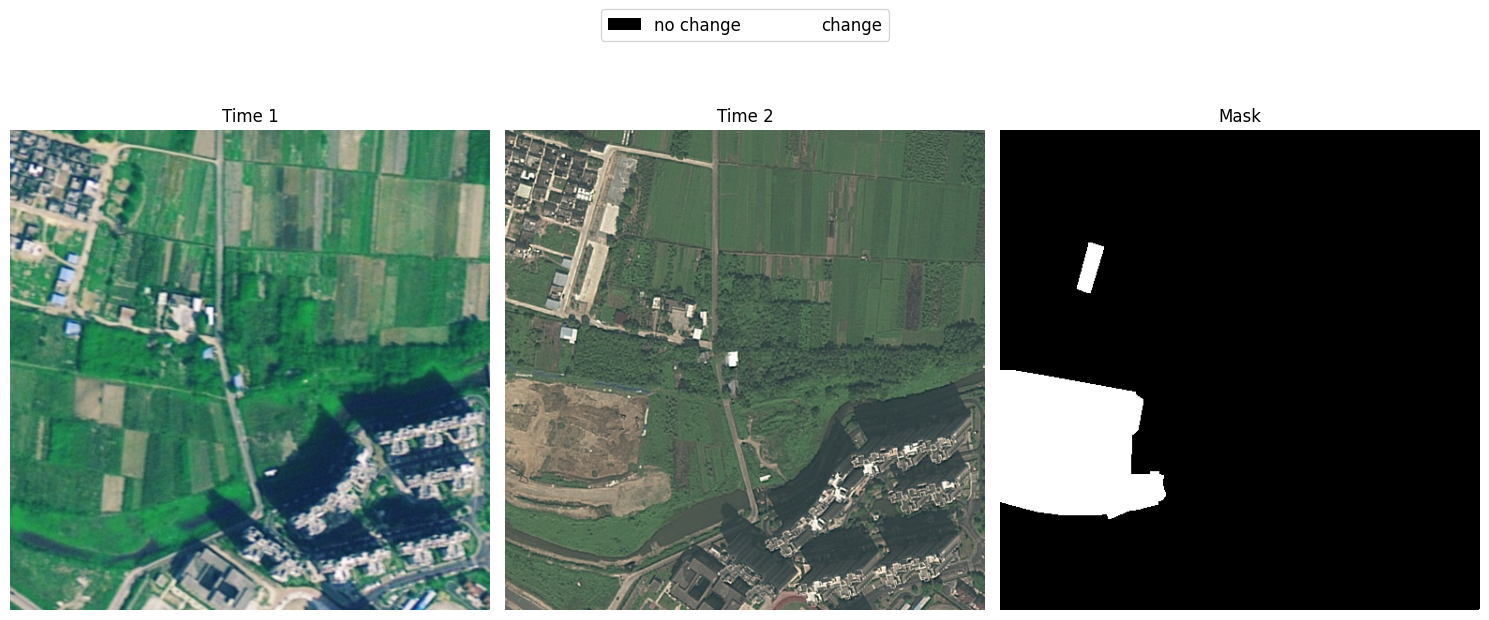

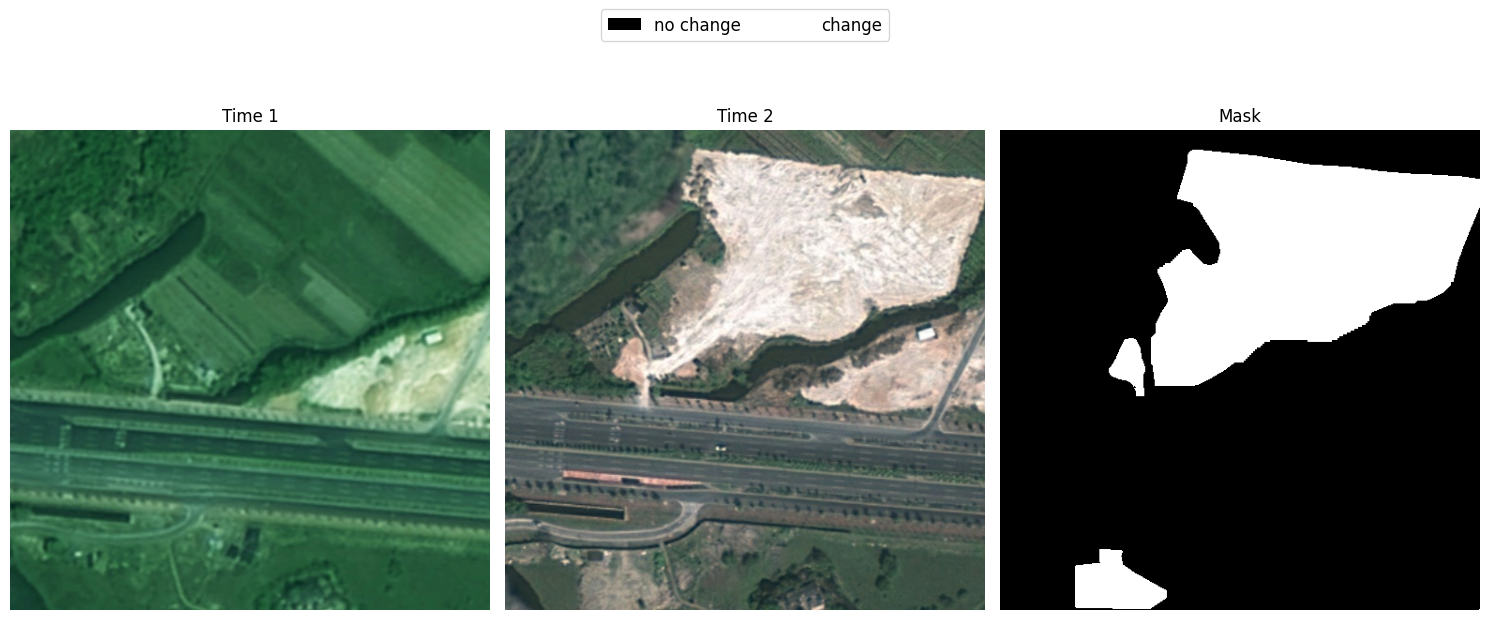

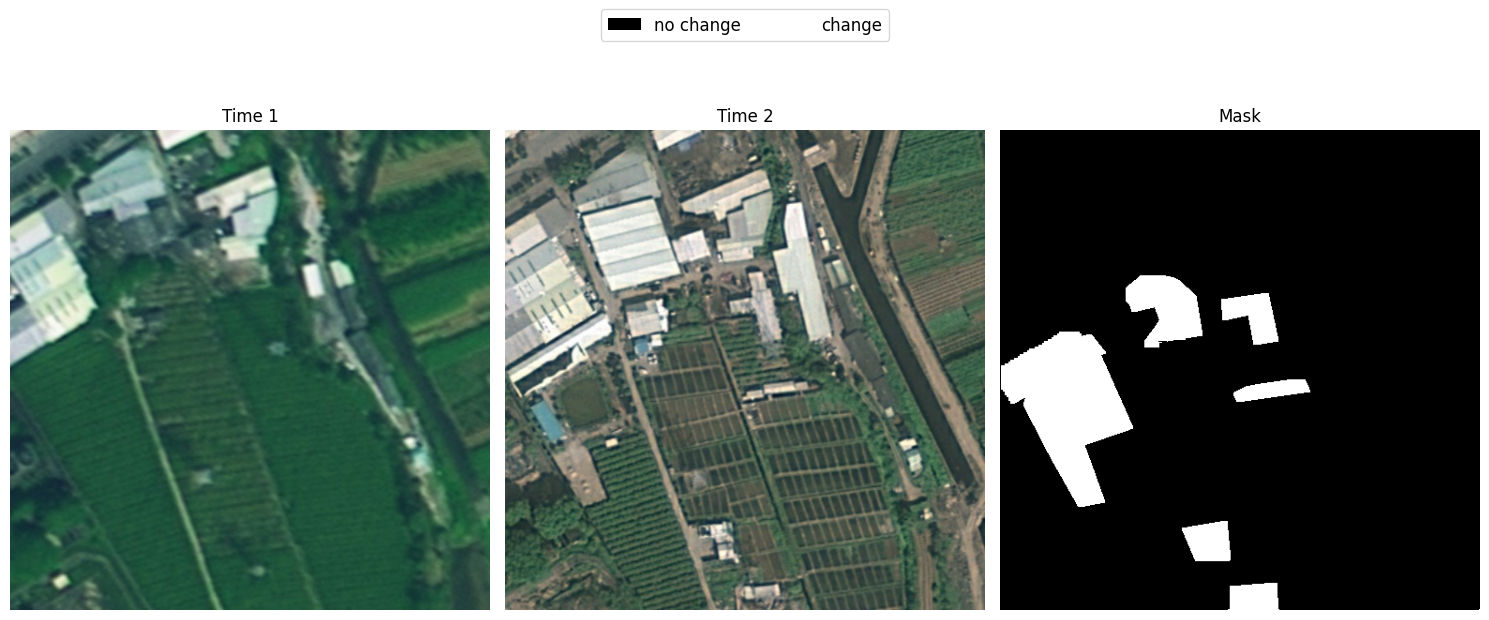

In [ ]:
dataset.show_image(100);
dataset.show_image(15);
dataset.show_image(22);

In [6]:
dataset.data_distribution_table()

,Number of pixels
no change,87152918.0
change,7218922.0


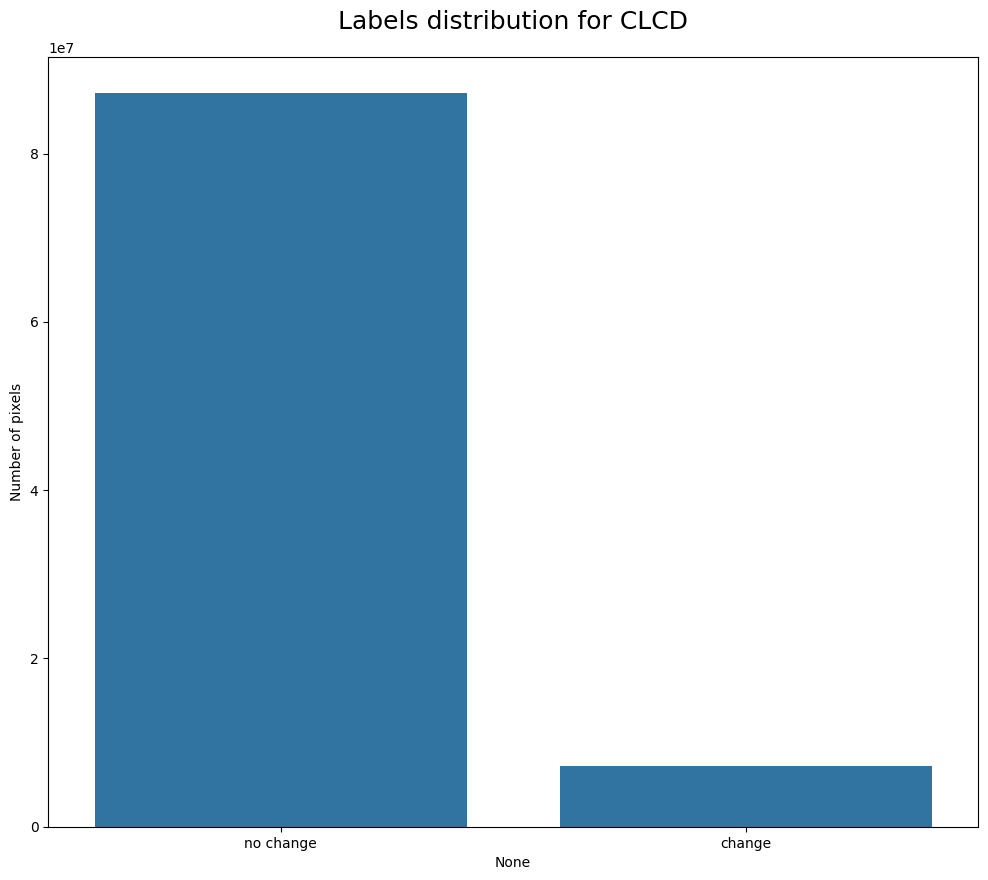

In [12]:
dataset.data_distribution_barchart();

## Load training and test data

In [9]:
train_dataset_config = {
    "batch_size": 16,
    "shuffle": True,
    "num_workers": 4,
    "data_dir" : "/home/dragik/data/FAIR_EO/clcd/train/",
    "transforms": ["aitlas.transforms.MinMaxNormTranspose","aitlas.transforms.ResizeToTensor"],
    "target_transforms": ["aitlas.transforms.Transpose","aitlas.transforms.ResizePerChannelToTensor"]
}
train_dataset = CLCDDataset(train_dataset_config)

test_dataset_config = {
    "batch_size": 8,
    "shuffle": True,
    "num_workers": 4,
    "data_dir" : "/home/dragik/data/FAIR_EO/clcd/val/",
    "transforms": ["aitlas.transforms.MinMaxNormTranspose","aitlas.transforms.ResizeToTensor"],
    "target_transforms": ["aitlas.transforms.Transpose","aitlas.transforms.ResizePerChannelToTensor"]
}
test_dataset = CLCDDataset(test_dataset_config)
len(train_dataset), len(test_dataset)

(360, 120)

## Create the model

In [10]:
epochs = 50
model_directory = "/home/dragik/data/FAIR_EO/experiments/clcd"
model_config = {
    "num_classes": 2, 
    "learning_rate": 0.0001,
    "pretrained": False, 
    "threshold": 0.5,
    "metrics": ["accuracy", "precision", "recall", "f1_score", "iou"]
}

model = UnetChangeDetection(model_config)
model.prepare()

## Start the training

In [11]:
model.train_and_evaluate_model(
    train_dataset=train_dataset,
    epochs=epochs,
    model_directory=model_directory,
    run_id='1',
)

model_path = model_directory + "/checkpoint.pth.tar"
model.load_model(model_path)
model.running_metrics.reset()
model.evaluate(dataset=test_dataset, model_path=model_path)
test_metrics = model.running_metrics.get_scores(model.metrics)

2026-01-28 07:56:12,303 INFO Starting training.
training: 100%|██████████| 23/23 [00:44<00:00,  1.95s/it]
2026-01-28 07:56:57,354 INFO epoch: 1, loss:  0.30687
testing on train set: 100%|██████████| 23/23 [00:45<00:00,  1.97s/it]
2026-01-28 07:57:43,681 INFO Accuracy:0.5061769061618381, Accuracy per Class:[0.08280695 0.92954686], Precision Micro:0.1964203763194126, Precision Macro:0.4988314610180905, Precision Weighted:0.8855730030271222, Precision per Class:[0.94986072 0.0478022 ], Recall Micro:1.8368961536510414e-05, Recall Macro:3.40751738221195e-05, Recall Weighted:1.8368961536510414e-05, Recall per Class:[1.57581311e-05 5.23922166e-05], F1_score Micro:3.673448771460958e-05, F1_score Macro:6.809272611613883e-05, F1_score Weighted:3.6729261634358344e-05, F1_score per Class:[3.15157393e-05 1.04669713e-04], IOU:1.8367581219148204e-05, IOU mean:3.404785675552944e-05, IOU per Class:[1.57581180e-05 5.23375955e-05]
training: 100%|██████████| 23/23 [00:48<00:00,  2.13s/it]
2026-01-28 07:58

## Predictions

2026-01-28 09:42:22,229 INFO Loading checkpoint /home/dragik/data/FAIR_EO/experiments/clcd/checkpoint.pth.tar
2026-01-28 09:42:22,641 INFO Loaded checkpoint /home/dragik/data/FAIR_EO/experiments/clcd/checkpoint.pth.tar at epoch 51


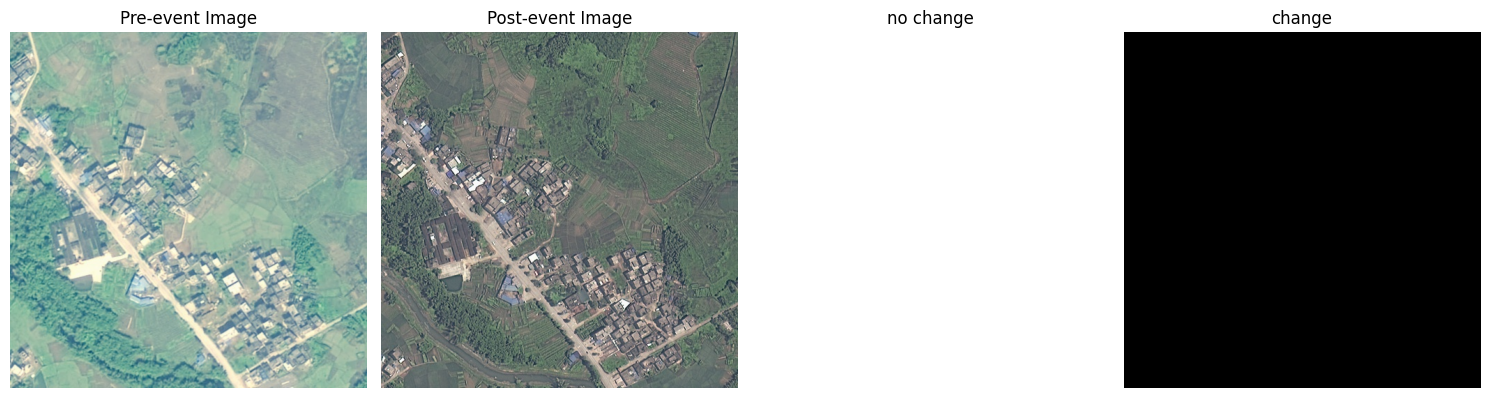

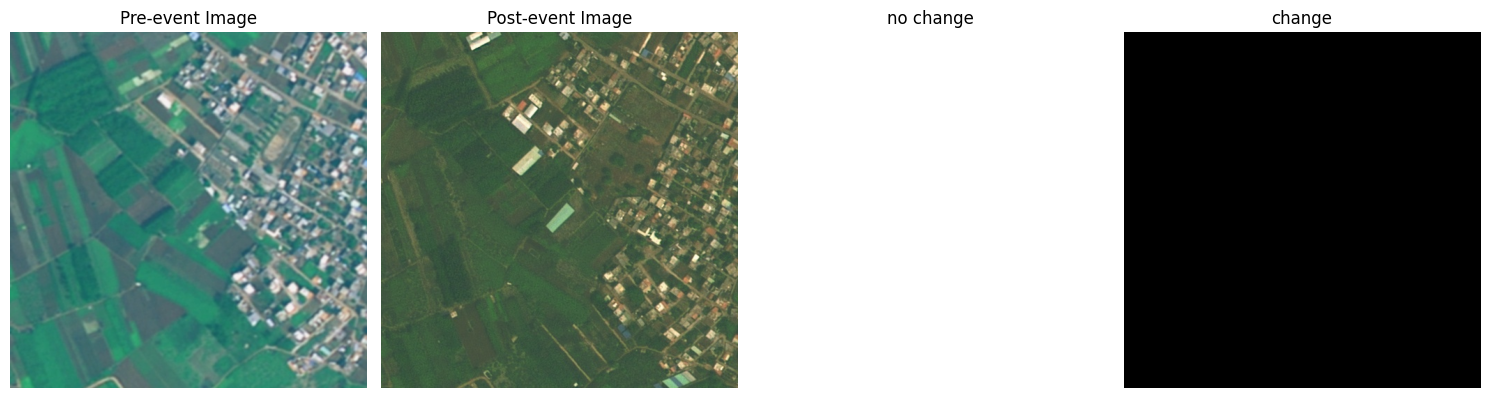

In [12]:
model_path = "/home/dragik/data/FAIR_EO/experiments/clcd/checkpoint.pth.tar"
labels = ["no change","change"]
transform = ResizeToTensor()
model.load_model(model_path)

image1 = image_loader("/home/dragik/data/FAIR_EO/clcd/test/time1/00483.png")
image2 = image_loader("/home/dragik/data/FAIR_EO/clcd/test/time2/00483.png")
fig = model.predict_masks(image1, image2, labels, transform)

image1 = image_loader("/home/dragik/data/FAIR_EO/clcd/test/time1/00551.png")
image2 = image_loader("/home/dragik/data/FAIR_EO/clcd/test/time2/00551.png")
fig = model.predict_masks(image1, image2, labels, transform)